In [1]:
# Lecture 12
# import packages
from scipy.stats import chi2
from scipy.special import logit, expit

from statsmodels.api import MNLogit
from statsmodels.formula.api import glm
from statsmodels.genmod.families import Binomial
from statsmodels.genmod.families import Poisson
from statsmodels.miscmodels.ordinal_model import OrderedModel

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import patsy
import os
# os.chdir(r'C:\Users\Linda\Desktop\ST5213py')
pd.set_option("display.width", 2000)

# import custom functions
from ST5213_helpers import *

# fig_save_dir = r'C:/Users/Linda/OneDrive - National University of Singapore/ST5213 2627/Lectures/Lecture_12/figure'

In [2]:
# Read knee dataset 
df = pd.read_csv('dataset/knee.txt', sep=' ')
print(df.head(), '\n')

# Set sex, th and y as categorical variables
df['sex'] = pd.Categorical(df['sex']) 
df['th'] = pd.Categorical(df['th'])
df['y'] = pd.Categorical(df['y'], categories=[1, 2, 3, 4, 5], ordered=True)
print(df.info())

      sex  age       th  y
0  female   28  placebo  4
1  female   32  placebo  4
2  female   41  placebo  3
3  female   21    spray  2
4  female   34    spray  2 

<class 'pandas.DataFrame'>
RangeIndex: 127 entries, 0 to 126
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype   
---  ------  --------------  -----   
 0   sex     127 non-null    category
 1   age     127 non-null    int64   
 2   th      127 non-null    category
 3   y       127 non-null    category
dtypes: category(3), int64(1)
memory usage: 1.9 KB
None


In [3]:
# Fit proportional odds models with all predictors as main terms
y = df['y'].cat.codes
X = patsy.dmatrix('th + sex + age', df, return_type='dataframe')
fm1 = OrderedModel(y, X.iloc[:,1:], distr='logit').fit(method='bfgs', disp=False)
print(fm1.summary())

                             OrderedModel Results                             
Dep. Variable:                      y   Log-Likelihood:                -186.12
Model:                   OrderedModel   AIC:                             386.2
Method:            Maximum Likelihood   BIC:                             406.2
Date:                Mon, 02 Nov 2026                                         
Time:                        12:03:06                                         
No. Observations:                 127                                         
Df Residuals:                     120                                         
Df Model:                           3                                         
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
th[T.spray]    -0.9438      0.336     -2.813      0.005      -1.601      -0.286
sex[T.male]    -0.0499      0.373     -0.134     

In [4]:
# Add age^2 term
X = patsy.dmatrix('th + sex + age + I(age**2)', df, return_type='dataframe')
fm1a = OrderedModel(y, X.iloc[:,1:], distr='logit').fit(method='bfgs', disp=False)
# print(fm1a.summary())

# Add age^3 term
X = patsy.dmatrix('th + sex + age + I(age**2) + I(age**3)', df, return_type='dataframe')
fm1b = OrderedModel(y, X.iloc[:,1:], distr='logit').fit(method='bfgs', disp=False)
# print(fm1b.summary())

print(anova_nested(fm1, fm1a, fm1b))

         Resid. Df  Resid. Dev   Df  Deviance  Pr(>Chi)
Model 1      120.0  372.247100  NaN       NaN       NaN
Model 2      119.0  362.884166  1.0  9.362933  0.002214
Model 3      118.0  362.868093  1.0  0.016074  0.899113


c:\Users\YuxinLi\anaconda3\envs\ST5213\Lib\site-packages\statsmodels\base\model.py:1189: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = fit_method(


In [5]:
# compute correlation matrix of fm1a
def compute_corr(model):
    cov = model.cov_params().to_numpy()
    std = np.sqrt(np.diag(cov))
    corr = cov / np.outer(std, std)
    return pd.DataFrame(corr, index=model.cov_params().index, columns=model.cov_params().columns)

print(compute_corr(fm1a).round(2), '\n')

print(min(df['age']), max(df['age']))
print(df['age'].corr(df['age']**2))
print(df['age'].mean())

# Center the variable age
df['agec'] = df['age'] - 30
print(df['agec'].corr(df['agec']**2))

             th[T.spray]  sex[T.male]   age  I(age ** 2)   0/1   1/2   2/3   3/4
th[T.spray]         1.00        -0.09 -0.01         0.03  0.13 -0.13 -0.19 -0.08
sex[T.male]        -0.09         1.00  0.11        -0.12  0.12 -0.02  0.03  0.04
age                -0.01         0.11  1.00        -0.99  0.98  0.16  0.11  0.03
I(age ** 2)         0.03        -0.12 -0.99         1.00 -0.95 -0.16 -0.12 -0.04
0/1                 0.13         0.12  0.98        -0.95  1.00  0.08  0.07  0.02
1/2                -0.13        -0.02  0.16        -0.16  0.08  1.00 -0.09 -0.02
2/3                -0.19         0.03  0.11        -0.12  0.07 -0.09  1.00 -0.06
3/4                -0.08         0.04  0.03        -0.04  0.02 -0.02 -0.06  1.00 

14 52
0.990915713476128
29.53543307086614
0.3587484574302215


In [6]:
# refit model using agec
X = patsy.dmatrix('th + sex + agec + I(agec**2)', df, return_type='dataframe')
fm2 = OrderedModel(y, X.iloc[:,1:], distr='logit').fit(method='bfgs', disp=False)
print(compute_corr(fm2).round(2), '\n')
print(drop1_po(fm2, X))
# print(fm2.summary())

# Drop sex term
X = patsy.dmatrix('th + agec + I(agec**2)', df, return_type='dataframe')
fm3 = OrderedModel(y, X.iloc[:,1:], distr='logit').fit(method='bfgs', disp=False)
print(drop1_po(fm3, X))
# print(fm3.summary())

              th[T.spray]  sex[T.male]  agec  I(agec ** 2)   0/1   1/2   2/3   3/4
th[T.spray]          1.00        -0.09  0.18          0.03  0.55 -0.13 -0.19 -0.08
sex[T.male]         -0.09         1.00 -0.09         -0.12  0.15 -0.02  0.03  0.04
agec                 0.18        -0.09  1.00         -0.29 -0.12  0.03  0.02 -0.02
I(agec ** 2)         0.03        -0.12 -0.29          1.00  0.58 -0.16 -0.12 -0.04
0/1                  0.55         0.15 -0.12          0.58  1.00 -0.48 -0.26 -0.08
1/2                 -0.13        -0.02  0.03         -0.16 -0.48  1.00 -0.09 -0.02
2/3                 -0.19         0.03  0.02         -0.12 -0.26 -0.09  1.00 -0.06
3/4                 -0.08         0.04 -0.02         -0.04 -0.08 -0.02 -0.06  1.00 

        Dropped   Df    Deviance         AIC       LRT  Pr(>Chi)
0        <none>       362.884166  378.884166                    
1            th  1.0  370.853994  384.853994  7.969828  0.004756
2           sex  1.0  362.932220  376.932220  0.048054  

-16 22
       0      1      2      3      4
0  0.603  0.240  0.093  0.055  0.009
1  0.556  0.260  0.108  0.066  0.011
2  0.511  0.276  0.123  0.077  0.013
3  0.468  0.288  0.138  0.090  0.015
4  0.430  0.297  0.152  0.103  0.018 

0    1.0
1    1.0
2    1.0
3    1.0
4    1.0
dtype: float64


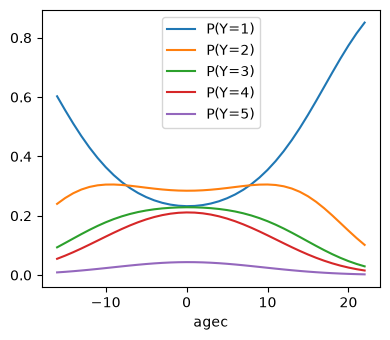

In [7]:
# predicted probabilities for spray group
print(min(df['agec']), max(df['agec']))
agec_new = np.array(range(-16, 23))
X_new = pd.DataFrame({'th': 1, 'agec':agec_new, 'I(agec**2)':agec_new**2})
probs = fm3.predict(X_new)
print(probs.head().round(3), '\n')
print(probs.sum(axis=1).head())

# plot predicted probabilities
plt.figure(figsize=(4, 3.5)) 
for i in range(5):
    plt.plot(agec_new, probs[i], label=f'P(Y={i+1})')

plt.legend()
plt.xlabel('agec')
plt.tight_layout()

# fig_path = os.path.join(fig_save_dir, 'knee_catprob.pdf')
# plt.savefig(fig_path, bbox_inches="tight")  

          0         1         2         3    4
0  0.602632  0.842681  0.936134  0.990979  1.0
1  0.555574  0.815340  0.923561  0.989077  1.0
2  0.510581  0.786541  0.909772  0.986939  1.0
3  0.468484  0.756878  0.894946  0.984579  1.0
4  0.429851  0.726991  0.879326  0.982018  1.0


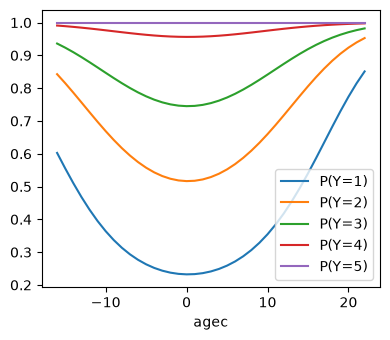

In [8]:
# Compute cumulative probabilities for spray group
cum_probs = probs.cumsum(axis=1)
print(cum_probs.head())

# plot cumulative predicted probabilities
plt.figure(figsize=(4, 3.5)) 
for i in range(5):
    plt.plot(agec_new, cum_probs[i], label=f'P(Y={i+1})')

plt.legend()
plt.xlabel('agec')
plt.tight_layout()

# fig_path = os.path.join(fig_save_dir, 'knee_cumprob.pdf')
# plt.savefig(fig_path, bbox_inches="tight")  

In [9]:
print(fm3.summary())

                             OrderedModel Results                             
Dep. Variable:                      y   Log-Likelihood:                -181.47
Model:                   OrderedModel   AIC:                             376.9
Method:            Maximum Likelihood   BIC:                             396.8
Date:                Mon, 02 Nov 2026                                         
Time:                        13:45:39                                         
No. Observations:                 127                                         
Df Residuals:                     120                                         
Df Model:                           3                                         
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
th[T.spray]     -0.9379      0.337     -2.781      0.005      -1.599      -0.277
agec             0.0021      0.018      0.116 

In [12]:
# Distinct intercepts
cutpoints = fm3.model.transform_threshold_params(fm3.params)[1:-1]
print(cutpoints.round(4))
print(np.exp(cutpoints), '\n')

slopes = fm3.params[:fm3.model.exog.shape[1]]
print(slopes, '\n')
print(np.exp(-slopes))

[-2.1332 -0.8714  0.1353  2.1495]
[0.11845345 0.41838002 1.14486269 8.58014475] 

th[T.spray]    -0.937914
agec            0.002081
I(agec ** 2)   -0.006166
dtype: float64 

th[T.spray]     2.554648
agec            0.997921
I(agec ** 2)    1.006185
dtype: float64


In [13]:
# Separate cumulative logit models 
df['f1'] = (df['y'] <= 1).astype(int)
df['f2'] = (df['y'] <= 2).astype(int)
df['f3'] = (df['y'] <= 3).astype(int)
df['f4'] = (df['y'] <= 4).astype(int)
print(df.head)

df['f1'] = pd.Categorical(df['f1'], categories=[1,0], ordered=True)
df['f2'] = pd.Categorical(df['f2'], categories=[1,0], ordered=True)
df['f3'] = pd.Categorical(df['f3'], categories=[1,0], ordered=True)
df['f4'] = pd.Categorical(df['f4'], categories=[1,0], ordered=True)

# fit separate logistic regression models
fmc1 = glm(formula='f1 ~ th + agec + I(agec**2)', data=df, family=Binomial()).fit()
fmc2 = glm(formula='f2 ~ th + agec + I(agec**2)', data=df, family=Binomial()).fit()
fmc3 = glm(formula='f3 ~ th + agec + I(agec**2)', data=df, family=Binomial()).fit()
fmc4 = glm(formula='f4 ~ th + agec + I(agec**2)', data=df, family=Binomial()).fit()

<bound method NDFrame.head of         sex  age       th  y  agec  f1  f2  f3  f4
0    female   28  placebo  4    -2   0   0   0   1
1    female   32  placebo  4     2   0   0   0   1
2    female   41  placebo  3    11   0   0   1   1
3    female   21    spray  2    -9   0   1   1   1
4    female   34    spray  2     4   0   1   1   1
..      ...  ...      ... ..   ...  ..  ..  ..  ..
122    male   28  placebo  1    -2   1   1   1   1
123  female   52  placebo  1    22   1   1   1   1
124  female   31  placebo  1     1   1   1   1   1
125  female   21    spray  1    -9   1   1   1   1
126    male   50    spray  1    20   1   1   1   1

[127 rows x 9 columns]>


In [14]:
# examine coeff and standard errors
print(fmc1.summary2().tables[1].round(3), '\n')
print(fmc2.summary2().tables[1].round(3), '\n')
print(fmc3.summary2().tables[1].round(3), '\n')
print(fmc4.summary2().tables[1].round(3), '\n')
print(fm3.summary().tables[1])

              Coef.  Std.Err.      z  P>|z|  [0.025  0.975]
Intercept    -1.618     0.393 -4.120  0.000  -2.387  -0.848
th[T.spray]   0.147     0.409  0.360  0.719  -0.654   0.948
agec         -0.008     0.021 -0.357  0.721  -0.050   0.034
I(agec ** 2)  0.006     0.002  2.478  0.013   0.001   0.011 

              Coef.  Std.Err.      z  P>|z|  [0.025  0.975]
Intercept    -1.131     0.369 -3.067  0.002  -1.854  -0.408
th[T.spray]   1.350     0.394  3.425  0.001   0.577   2.122
agec         -0.016     0.022 -0.728  0.467  -0.059   0.027
I(agec ** 2)  0.007     0.003  2.802  0.005   0.002   0.012 

              Coef.  Std.Err.      z  P>|z|  [0.025  0.975]
Intercept    -0.042     0.367 -0.114  0.910  -0.761   0.677
th[T.spray]   1.519     0.469  3.237  0.001   0.599   2.439
agec          0.005     0.026  0.180  0.857  -0.046   0.055
I(agec ** 2)  0.006     0.003  1.887  0.059  -0.000   0.012 

              Coef.  Std.Err.      z  P>|z|  [0.025  0.975]
Intercept     2.637     0.778  3.3

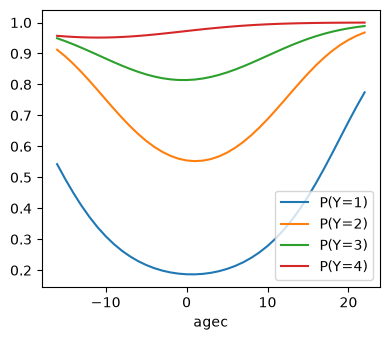

In [15]:
# compute predictions 
df_new = pd.DataFrame({'th': 'spray', 'agec':agec_new, 'I(agec**2)':agec_new**2})
cum_fmc1 = fmc1.predict(df_new)
cum_fmc2 = fmc2.predict(df_new)
cum_fmc3 = fmc3.predict(df_new)
cum_fmc4 = fmc4.predict(df_new)

# plot cumulative predicted probabilities
plt.figure(figsize=(4, 3.5)) 
plt.plot(agec_new, cum_fmc1, label=f'P(Y=1)')
plt.plot(agec_new, cum_fmc2, label=f'P(Y=2)')
plt.plot(agec_new, cum_fmc3, label=f'P(Y=3)')
plt.plot(agec_new, cum_fmc4, label=f'P(Y=4)')

plt.legend()
plt.xlabel('agec')
plt.tight_layout()

# fig_path = os.path.join(fig_save_dir, 'sep_logreg.pdf')
# plt.savefig(fig_path, bbox_inches="tight")  

In [16]:
# Read housing data
df = pd.read_csv('dataset/housing.txt', sep=' ')
print(df.head(), '\n')

# Set variables as categorical
df['Sat'] = pd.Categorical(df['Sat'], categories=['Low', 'Medium', 'High'])
df['Cont'] = pd.Categorical(df['Cont'], categories=['Low', 'High'])
df['Infl'] = pd.Categorical(df['Infl'], categories=['Low', 'Medium', 'High'])
df['Type'] = pd.Categorical(df['Type'], categories=['Tower', 'Apartment', 'Atrium', 'Terrace'])
print(df.info(), '\n')

# view as contingency table 
tab = df.pivot(index=['Infl', 'Type', 'Cont'], columns='Sat', values='Freq').sort_index() 
print(tab)

# unroll data into long form (individual observations)
df_long = df.loc[df.index.repeat(df['Freq'])].reset_index(drop=True)

      Sat    Infl   Type Cont  Freq
1     Low     Low  Tower  Low    21
2  Medium     Low  Tower  Low    21
3    High     Low  Tower  Low    28
4     Low  Medium  Tower  Low    34
5  Medium  Medium  Tower  Low    22 

<class 'pandas.DataFrame'>
RangeIndex: 72 entries, 1 to 72
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype   
---  ------  --------------  -----   
 0   Sat     72 non-null     category
 1   Infl    72 non-null     category
 2   Type    72 non-null     category
 3   Cont    72 non-null     category
 4   Freq    72 non-null     int64   
dtypes: category(4), int64(1)
memory usage: 1.6 KB
None 

Sat                    Low  Medium  High
Infl   Type      Cont                   
Low    Tower     Low    21      21    28
                 High   14      19    37
       Apartment Low    61      23    17
                 High   78      46    43
       Atrium    Low    13       9    10
                 High   20      23    20
       Terrace   Low    18       6     

In [17]:
# fit multinomial logit model using loglinear model and perform model selection starting from full model
fm_loglinear = glm(formula='Freq ~ Sat*Infl*Type*Cont', data=df, family=Poisson()).fit()
print(drop1_glm(fm_loglinear))

fm_loglinear = update_glm(fm_loglinear, drop='Sat:Infl:Type:Cont')
print(drop1_glm(fm_loglinear))

fm_loglinear = update_glm(fm_loglinear, drop='Sat:Infl:Cont')
print(drop1_glm(fm_loglinear))

fm_loglinear = update_glm(fm_loglinear, drop='Sat:Type:Cont')
print(drop1_glm(fm_loglinear))

fm_loglinear = update_glm(fm_loglinear, drop='Sat:Infl:Type')
print(drop1_glm(fm_loglinear))

                    Df      Deviance         AIC       LRT  Pr(>Chi)
<none>                 -1.554312e-15  484.969606                    
Sat:Infl:Type:Cont  12  5.944319e+00  466.913925  5.944319  0.918863
                Df   Deviance         AIC        LRT  Pr(>Chi)
<none>               5.944319  466.913925                     
Sat:Infl:Type   12  27.002402  463.972008  21.058084  0.049536
Sat:Infl:Cont    4   6.828381  459.797987   0.884062  0.926836
Sat:Type:Cont    6  15.234088  464.203694   9.289769  0.157925
Infl:Type:Cont   6  10.007041  458.976647   4.062722  0.668189
                Df   Deviance         AIC        LRT  Pr(>Chi)
<none>               6.828381  459.797987                     
Sat:Infl:Type   12  28.255854  457.225460  21.427473   0.04446
Sat:Type:Cont    6  16.107157  457.076763   9.278776  0.158496
Infl:Type:Cont   6  10.882256  451.851862   4.053875  0.669386
                Df   Deviance         AIC        LRT  Pr(>Chi)
<none>              16.107157  457.07

c:\Users\YuxinLi\anaconda3\envs\ST5213\Lib\site-packages\statsmodels\regression\_tools.py:133: RuntimeWarning: divide by zero encountered in scalar divide
  scale = np.dot(wresid, wresid) / df_resid
c:\Users\YuxinLi\anaconda3\envs\ST5213\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:1269: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  return self._fit_irls(


In [18]:
# Predicted multinomial probabilities
fm_main = fm_loglinear
df['pred'] = fm_main.predict(df)
tab_pred = df.pivot(index=['Infl', 'Type', 'Cont'], columns='Sat', values='pred').sort_index() 
print(tab_pred.div(tab_pred.sum(axis=1), axis=0).round(3))

Sat                      Low  Medium   High
Infl   Type      Cont                      
Low    Tower     Low   0.396   0.260  0.344
                 High  0.298   0.281  0.420
       Apartment Low   0.543   0.231  0.226
                 High  0.438   0.267  0.295
       Atrium    Low   0.429   0.322  0.249
                 High  0.332   0.357  0.311
       Terrace   Low   0.645   0.218  0.137
                 High  0.547   0.265  0.188
Medium Tower     Low   0.260   0.267  0.472
                 High  0.185   0.272  0.543
       Apartment Low   0.395   0.262  0.343
                 High  0.297   0.284  0.419
       Atrium    Low   0.296   0.347  0.357
                 High  0.216   0.363  0.422
       Terrace   Low   0.508   0.268  0.224
                 High  0.404   0.306  0.289
High   Tower     Low   0.150   0.192  0.657
                 High  0.101   0.185  0.714
       Apartment Low   0.255   0.211  0.534
                 High  0.179   0.213  0.608
       Atrium    Low   0.187   0

In [20]:
# Alternatively, fit multinomial logit model directly using long form of data
y = df_long['Sat'].cat.codes

X = patsy.dmatrix('Infl*Type*Cont', df_long, return_type='dataframe')
fm_MNL = MNLogit(y, X).fit(method='newton', disp=False)
print(drop1_MNL(fm_MNL, X), '\n')

X = patsy.dmatrix('Infl*Type + Type*Cont + Infl*Cont', df_long, return_type='dataframe')
fm_MNL = MNLogit(y, X).fit(method='newton', disp=False)
print(drop1_MNL(fm_MNL, X), '\n')

X = patsy.dmatrix('Infl*Type + Type*Cont', df_long, return_type='dataframe')
fm_MNL = MNLogit(y, X).fit(method='newton', disp=False)
print(drop1_MNL(fm_MNL, X), '\n')

X = patsy.dmatrix('Cont + Infl*Type', df_long, return_type='dataframe')
fm_MNL = MNLogit(y, X).fit(method='newton', disp=False)
print(drop1_MNL(fm_MNL, X), '\n')

X = patsy.dmatrix('Cont + Infl + Type', df_long, return_type='dataframe')
fm_MNL = MNLogit(y, X).fit(method='newton', disp=False)
print(drop1_MNL(fm_MNL, X), '\n')

# Predicted counts if fm_main is fitted using MNLogit
combos = tab.index.to_frame(index=False)   # DataFrame with Infl, Type, Con
X_pred = patsy.dmatrix('Cont + Infl + Type', combos, return_type='dataframe')
prob = np.array(fm_MNL.predict(X_pred))
pred = pd.DataFrame(prob, index=tab.index, columns=tab.columns)
print(pred.head().round(3))

          Dropped    Df     Deviance          AIC       LRT  Pr(>Chi)
0          <none>        3431.421662  3527.421662                    
1  Infl:Type:Cont  12.0  3437.365980  3509.365980  5.944319  0.918863 

     Dropped    Df     Deviance          AIC        LRT  Pr(>Chi)
0     <none>        3437.365980  3509.365980                     
1  Infl:Type  12.0  3458.424064  3506.424064  21.058084  0.049536
2  Type:Cont   6.0  3446.655750  3506.655750   9.289769  0.157925
3  Infl:Cont   4.0  3438.250043  3502.250043   0.884062  0.926836 

     Dropped    Df     Deviance          AIC        LRT  Pr(>Chi)
0     <none>        3438.250043  3502.250043                     
1  Infl:Type  12.0  3459.677515  3499.677515  21.427473   0.04446
2  Type:Cont   6.0  3447.528819  3499.528819   9.278776  0.158496 

     Dropped    Df     Deviance          AIC        LRT  Pr(>Chi)
0     <none>        3447.528819  3499.528819                     
1       Cont   2.0  3464.293140  3512.293140  16.764321  0

In [21]:
# Compute cumulative probabilities across categories 
cum_prob = prob.cumsum(axis=1)
print(cum_prob[:5, :].round(3), '\n')

# compute log odds ratio
lor = logit(cum_prob[:,0]) - logit(cum_prob[:,1])
lor.sort()
print(lor.round(3), lor.mean().round(3), '\n')

[[0.396 0.656 1.   ]
 [0.298 0.58  1.   ]
 [0.543 0.774 1.   ]
 [0.438 0.705 1.   ]
 [0.429 0.751 1.   ]] 

[-1.607 -1.497 -1.495 -1.454 -1.39  -1.312 -1.306 -1.285 -1.275 -1.272
 -1.244 -1.209 -1.187 -1.177 -1.155 -1.12  -1.1   -1.082 -1.08  -1.077
 -1.068 -1.057 -0.985 -0.936] -1.224 



In [22]:
# Fit proportional odds model with all main terms
X = patsy.dmatrix('Cont + Infl + Type', df_long, return_type='dataframe')
fmp_main = OrderedModel(y, X.iloc[:,1:], distr='logit').fit(method='bfgs', disp=False)
print(fmp_main.summary())

                             OrderedModel Results                             
Dep. Variable:                      y   Log-Likelihood:                -1739.6
Model:                   OrderedModel   AIC:                             3495.
Method:            Maximum Likelihood   BIC:                             3539.
Date:                Mon, 02 Nov 2026                                         
Time:                        14:09:43                                         
No. Observations:                1681                                         
Df Residuals:                    1673                                         
Df Model:                           6                                         
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
Cont[T.High]          0.3603      0.096      3.772      0.000       0.173       0.548
Infl[T.Medium]        0.5664   

In [23]:
print(fm_MNL.aic, fmp_main.aic)

3498.0838663411223 3495.149299837065


In [24]:
# Fit proportional odds model
X = patsy.dmatrix('Infl*Type*Cont', df_long, return_type='dataframe')
fmp_full = OrderedModel(y, X.iloc[:, 1:], distr='logit').fit(method='bfgs', disp=False)
print(drop1_po(fmp_full, X), '\n')

X = patsy.dmatrix('Infl*Type + Infl*Cont + Type*Cont', df_long, return_type='dataframe')
fm = OrderedModel(y, X.iloc[:, 1:], distr='logit').fit(method='bfgs', disp=False)
print(drop1_po(fm, X), '\n')

X = patsy.dmatrix('Infl*Type + Type*Cont', df_long, return_type='dataframe')
fm = OrderedModel(y, X.iloc[:, 1:], distr='logit').fit(method='bfgs', disp=False)
print(drop1_po(fm, X), '\n')

X = patsy.dmatrix('Infl*Type + Cont', df_long, return_type='dataframe')
fm = OrderedModel(y, X.iloc[:, 1:], distr='logit').fit(method='bfgs', disp=False)
print(drop1_po(fm, X),)

          Dropped   Df     Deviance          AIC       LRT  Pr(>Chi)
0          <none>       3446.458487  3496.458487                    
1  Infl:Type:Cont  6.0  3448.583374  3486.583374  2.124887  0.907862 

     Dropped   Df     Deviance          AIC        LRT  Pr(>Chi)
0     <none>       3448.583374  3486.583374                     
1  Infl:Type  6.0  3470.300753  3496.300753  21.717379  0.001362
2  Infl:Cont  2.0  3448.694982  3482.694982   0.111608  0.945724
3  Type:Cont  3.0  3456.507902  3488.507902   7.924528  0.047598 

     Dropped   Df     Deviance          AIC        LRT  Pr(>Chi)
0     <none>       3448.694982  3482.694982                     
1  Infl:Type  6.0  3470.483147  3492.483147  21.788166  0.001323
2  Type:Cont  3.0  3456.639963  3484.639963   7.944981  0.047163 

     Dropped   Df     Deviance          AIC        LRT  Pr(>Chi)
0     <none>       3456.639963  3484.639963                     
1       Cont  1.0  3471.760392  3497.760392  15.120429  0.000101
2  Infl

In [25]:
print(fm.summary())
# Distinct intercepts
cutpoints = fm.model.transform_threshold_params(fm.params)[1:-1]
print(cutpoints, cutpoints[0] -cutpoints[1])

                             OrderedModel Results                             
Dep. Variable:                      y   Log-Likelihood:                -1728.3
Model:                   OrderedModel   AIC:                             3485.
Method:            Maximum Likelihood   BIC:                             3561.
Date:                Mon, 02 Nov 2026                                         
Time:                        14:10:46                                         
No. Observations:                1681                                         
Df Residuals:                    1667                                         
Df Model:                          12                                         
                                       coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------------
Infl[T.Medium]                      -0.1389      0.213     -0.654      0.513      -0.55